# Approximate sufficiency: three numbers a season

Logistic regression with a per-observation offset is the standard case where exact compression fails.
Goals $G=\sum_i y_i$ are exactly sufficient for the skill parameter below (a canonical-link GLM always has a
sufficient statistic for the outcome), but the log-likelihood's normalising term $\sum_i \log(1+e^{\text{offset}_i+\eta})$
still runs over every row. That is the finishing-skill problem from the
[football factor model](https://nathanielf.github.io/football_models_with_wyatt/). Each shot $i$ arrives with
a pre-shot goal probability $p_i$ (an xG model's estimate); a player's finishing skill $\eta$ shifts its log-odds:

$$\Pr(\text{goal}_i) = \operatorname{logit}^{-1}(\operatorname{logit} p_i + \eta).$$

The exact log-likelihood needs every shot. Expand it to second order around $\eta = 0$:

$$\ell(\eta) \approx \ell(0) + (G - X)\,\eta - \tfrac12 V \eta^2, \qquad G=\sum_i y_i,\; X=\sum_i p_i,\; V=\sum_i p_i(1-p_i).$$

Goals, expected goals, and the Bernoulli variance of expected goals. $(G, X, V)$ is *approximately*
sufficient, and the approximation is good precisely where it is needed: skill effects are small, so
$\eta$ lives near the expansion point. Completing the square shows it is a Gaussian pseudo-observation:

$$\hat\eta = \frac{G - X}{V} \;\sim\; \mathcal N\!\left(\eta,\; 1/\sqrt V\right),$$

which means we can use an ordinary `pm.Normal` and keep the pointwise log-likelihood that a
`pm.Potential` would lose.

In [1]:
import time
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy.special import expit, logit

rng = np.random.default_rng(606)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)


def timed_fit(model, label, n_rows, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    return idata, {"model": label, "rows in likelihood": n_rows, "wall time (s)": round(secs, 1),
                   "min ESS/s": round(ess / secs, 1)}

## Shots, players, and how good the quadratic is

A simulator we can reuse: `n_players` players, each taking a few dozen to a few hundred shots with
heterogeneous xG, and a true finishing skill drawn with spread `tau`.

In [2]:
def simulate(n_players, tau):
    eta = rng.normal(0, tau, n_players)
    n_shots = rng.integers(30, 300, n_players)
    player = np.repeat(np.arange(n_players), n_shots)
    xg = rng.beta(0.6, 4.2, len(player))                       # skewed: mostly low-quality chances
    goal = rng.binomial(1, expit(logit(xg) + eta[player]))
    return eta, pd.DataFrame({"player": player, "xg": xg, "goal": goal})


def summarise(shots, eta0=None):
    """(G, X, V) per player, optionally expanded around a player-specific point eta0."""
    off = logit(shots.xg.values) + (0 if eta0 is None else eta0[shots.player.values])
    q = expit(off)
    g = pd.DataFrame({"player": shots.player, "G": shots.goal, "X": q, "V": q * (1 - q)})
    return g.groupby("player").sum()

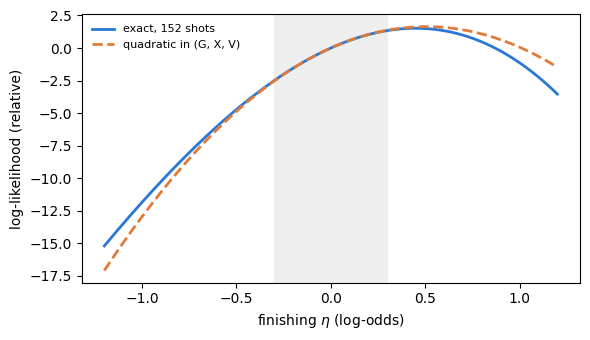

In [3]:
#| label: fig-approx-curve
#| fig-cap: "Exact shot-by-shot log-likelihood for one player (solid) against the three-number quadratic (dashed). Shaded: the range where realistic finishing effects live."
_, one = simulate(1, 0.0)
s = summarise(one).iloc[0]
grid = np.linspace(-1.2, 1.2, 241)
exact = np.array([(one.goal * (logit(one.xg) + e) - np.log1p(np.exp(logit(one.xg) + e))).sum() for e in grid])
exact -= exact[120]
quad = (s.G - s.X) * grid - 0.5 * s.V * grid**2
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.axvspan(-0.3, 0.3, color="#eeeeee")
ax.plot(grid, exact, color="#2a78d6", lw=2, label=f"exact, {len(one)} shots")
ax.plot(grid, quad, color="#e07b39", lw=2, ls="--", label="quadratic in (G, X, V)")
ax.set_xlabel(r"finishing $\eta$ (log-odds)")
ax.set_ylabel("log-likelihood (relative)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Hierarchical finishing model: every shot vs three numbers per player

Two worlds. In the realistic one, finishing skill has a spread of $\tau = 0.15$ on the log-odds scale.
In the stress test, $\tau = 0.8$, which would mean some players convert chances at twice the rate
of others: well outside the range where a quadratic around zero should be trusted. For the stress
test we also try the obvious repair: expand each player around a crude estimate $\eta_0$ (one Newton step
from zero), which needs one more pass over the shots but no more than that.

In [4]:
def model_full(shots, n_players):
    with pm.Model() as m:
        tau = pm.HalfNormal("tau", 0.5)
        eta = pm.Normal("eta", 0, tau, shape=n_players)
        pm.Bernoulli("goal", logit_p=logit(shots.xg.values) + eta[shots.player.values],
                     observed=shots.goal.values)
    return m


def model_suff(summ, n_players, eta0=None):
    eta0 = np.zeros(n_players) if eta0 is None else eta0
    with pm.Model() as m:
        tau = pm.HalfNormal("tau", 0.5)
        eta = pm.Normal("eta", 0, tau, shape=n_players)
        pm.Normal("eta_hat", mu=eta, sigma=1 / np.sqrt(summ.V.values),
                  observed=eta0 + (summ.G.values - summ.X.values) / summ.V.values)
    return m


results, records = {}, []
for world, tau_true in [("realistic", 0.15), ("stress", 0.8)]:
    n_players = 400
    eta_true, shots = simulate(n_players, tau_true)
    s0 = summarise(shots)
    fits = {"every shot": timed_fit(model_full(shots, n_players), f"{world}: Bernoulli per shot", len(shots)),
            "(G, X, V) at 0": timed_fit(model_suff(s0, n_players), f"{world}: (G, X, V) around 0", n_players)}
    if world == "stress":
        eta0 = np.clip((s0.G - s0.X) / s0.V, -2, 2).values   # one Newton step
        s1 = summarise(shots, eta0)
        fits["(G, X, V) at η0"] = timed_fit(model_suff(s1, n_players, eta0), f"{world}: (G, X, V) around η0", n_players)
    results[world] = (eta_true, {k: v[0] for k, v in fits.items()})
    records += [v[1] for v in fits.values()]

NUTS[nutpie]: [tau, eta]
NUTS[nutpie]: [tau, eta]
NUTS[nutpie]: [tau, eta]
NUTS[nutpie]: [tau, eta]
NUTS[nutpie]: [tau, eta]


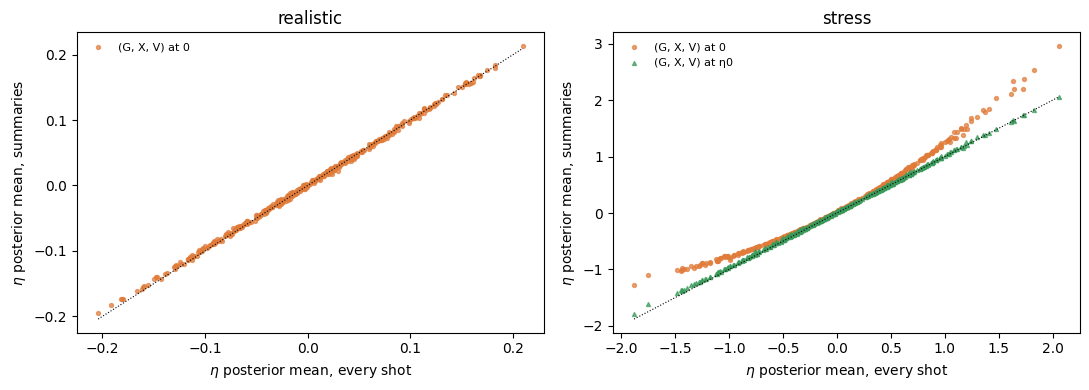

In [5]:
#| label: fig-approx-equiv
#| fig-cap: "Posterior mean finishing skill per player from the three-number summaries against the exact shot-level fit. Left: realistic spread, the points sit on the diagonal. Right: an implausibly wide spread; expanding around zero distorts the extremes (the quadratic misplaces the curvature far from zero), re-centring each player on a crude estimate fixes it."
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
styles = {"(G, X, V) at 0": dict(color="#e07b39", s=8), "(G, X, V) at η0": dict(color="#3a9a5b", s=8, marker="^")}
for ax, world in zip(axes, ["realistic", "stress"]):
    _, fits = results[world]
    ref = fits["every shot"].posterior["eta"].mean(("chain", "draw")).values
    for k, st in styles.items():
        if k in fits:
            ax.scatter(ref, fits[k].posterior["eta"].mean(("chain", "draw")).values, label=k, alpha=0.7, **st)
    lim = [ref.min(), ref.max()]
    ax.plot(lim, lim, "k:", lw=0.8)
    ax.set_title(world)
    ax.set_xlabel(r"$\eta$ posterior mean, every shot")
    ax.set_ylabel(r"$\eta$ posterior mean, summaries")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
#| label: tbl-approx-speed
#| tbl-cap: "Shot-level vs three-numbers-per-player fits, with the population spread τ each recovers."
speed = pd.DataFrame(records)
speed["tau mean"] = [float(f.posterior["tau"].mean()) for w in results for f in results[w][1].values()]
speed.round(3)

,model,rows in likelihood,wall time (s),min ESS/s,tau mean
0,realistic: Bernoulli per shot,65949,79.7,2.5,0.157
1,"realistic: (G, X, V) around 0",400,1.4,171.3,0.155
2,stress: Bernoulli per shot,66820,80.8,69.2,0.750
3,"stress: (G, X, V) around 0",400,0.9,7479.9,0.785
4,"stress: (G, X, V) around η0",400,0.8,8071.4,0.739


## Why it works, and when it does not

- It is a **Laplace / Gaussian approximation to each unit's likelihood**, computed once and reused by
  every model that sits on top. The hierarchy, priors and other structure stay exact; only the inner
  likelihood is summarised. The same move underlies meta-analysis (eight schools *is* this model: a
  per-unit estimate and standard error) and the "summary statistics" tradition in genetics.
- The error is the cubic term of the expansion, which scales with $|\eta - \eta_0|^3$ times the third
  cumulant of the shots. Small effects, or a good expansion point, make it negligible.
- Re-centring needs one more pass over raw data, so it is cheapest when the summaries are built in a
  pipeline that can be re-run, not when they arrive as a fixed table.
- Unlike the exact cases, these summaries are **not additive across expansion points**: $(G, X, V)$
  from two seasons can be summed only if they were expanded around the same $\eta_0$.